# 实验报告02：NumPy、SciPy、Matplotlib 与 pandas 数据处理

- **学号**：20244081108
- **姓名**：王亨泰
- **环境**：独立 conda 虚拟环境 `pyda`（Python 3.11 + Jupyter）

## 1.1 第一个代码框：身份与环境记录

In [1]:
import os
import uuid
import hashlib
import platform

import numpy as np
import scipy
import matplotlib
import pandas as pd

# 修改为自己的学号
STUDENT_ID = 20244081108

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] pyda
[学号]       20244081108
[机器指纹] e8b54e0f27d3d000
[RUN_ID]   20244081108-e8b54e0f27d3d000


---
## 实验1：NumPy 数组、数据类型与索引

### 1. 三种数据类型的 ndarray

In [2]:
# 1) 整数、浮点数和布尔值数组
a_int = np.array([1, 2, 3, 4])
a_float = np.array([1.0, 2.5, 3.0, 4.5])
a_bool = np.array([True, False, True, False])

for name, arr in [("整数", a_int), ("浮点", a_float), ("布尔", a_bool)]:
    print(f"{name}数组: {arr}")
    print(f"  dtype = {arr.dtype}, shape = {arr.shape}, ndim = {arr.ndim}")

整数数组: [1 2 3 4]
  dtype = int64, shape = (4,), ndim = 1
浮点数组: [1.  2.5 3.  4.5]
  dtype = float64, shape = (4,), ndim = 1
布尔数组: [ True False  True False]
  dtype = bool, shape = (4,), ndim = 1


**解释**：NumPy 数组要求所有元素类型一致（同质），因此有统一的 `dtype`，底层是一块连续的定长内存；Python 列表可以混放不同类型的对象，元素是对象的引用，因此没有统一的数值类型和固定形状。同质、连续存储让 NumPy 的向量化运算比 Python 循环快得多。

### 2. arange(12) 与 reshape

In [3]:
arr = np.arange(12)
print("原一维数组:", arr)

a34 = arr.reshape(3, 4)
a232 = arr.reshape(2, 3, 2)

print("\n(3, 4):")
print(a34)
print("shape =", a34.shape, "ndim =", a34.ndim)

print("\n(2, 3, 2):")
print(a232)
print("shape =", a232.shape, "ndim =", a232.ndim)

print("\n元素总数:", arr.size, "；3*4 =", 3 * 4, "；2*3*2 =", 2 * 3 * 2)

原一维数组: [ 0  1  2  3  4  5  6  7  8  9 10 11]

(3, 4):
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
shape = (3, 4) ndim = 2

(2, 3, 2):
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]
shape = (2, 3, 2) ndim = 3

元素总数: 12 ；3*4 = 12 ；2*3*2 = 12


**解释**：`reshape` 只改变数组的形状，不改变元素个数和顺序，因此新形状各维度的乘积必须等于原数组的元素总数（这里是 12）。不满足时会抛出 `ValueError`。

### 3. 对 (3, 4) 数组做索引

In [4]:
print("数组 a34:\n", a34)

row2 = a34[1]          # 第 2 行（下标从 0 开始）
col13 = a34[:, 0:3]    # 第 1 至第 3 列
big = a34[a34 > 6]     # 大于 6 的元素

print("\n第 2 行:", row2, "shape =", row2.shape)
print("第 1~3 列:\n", col13, "shape =", col13.shape)
print("大于 6 的元素:", big, "shape =", big.shape)

数组 a34:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

第 2 行: [4 5 6 7] shape = (4,)
第 1~3 列:
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] shape = (3, 3)
大于 6 的元素: [ 7  8  9 10 11] shape = (5,)


**解释**：`a34[1]` 取一行，结果是一维数组（shape `(4,)`）；`a34[:, 0:3]` 的切片是左闭右开，取列下标 0、1、2，结果是 `(3, 3)`；布尔索引 `a34[a34 > 6]` 会把所有满足条件的元素拉平成一维数组，因此 shape 是 `(5,)`（元素为 7~11）。

### 4. 布尔索引与逻辑运算

In [5]:
b = np.arange(10)
print("b =", b)

print("\n小于 2 或大于 7:", b[(b < 2) | (b > 7)])
print("大于 3 且小于 7:", b[(b > 3) & (b < 7)])
print("np.logical_or  :", b[np.logical_or(b < 2, b > 7)])
print("np.logical_and :", b[np.logical_and(b > 3, b < 7)])

b = [0 1 2 3 4 5 6 7 8 9]

小于 2 或大于 7: [0 1 8 9]
大于 3 且小于 7: [4 5 6]
np.logical_or  : [0 1 8 9]
np.logical_and : [4 5 6]


**解释**：`|`、`&` 的优先级高于比较运算符，所以每个比较必须加括号，写成 `(b < 2) | (b > 7)`；若写成 `b < 2 | b > 7`，Python 会先算 `2 | b`，结果不符合预期。`np.logical_or`/`np.logical_and` 与 `|`/`&` 等价，只是函数形式更明确。

### 5. 逐元素乘法与矩阵乘法

In [6]:
m1 = np.array([[1, 2], [3, 4]])
m2 = np.array([[5, 6], [7, 8]])

print("m1 =\n", m1)
print("m2 =\n", m2)
print("\nm1 * m2 (逐元素):\n", m1 * m2)
print("np.multiply(m1, m2):\n", np.multiply(m1, m2))
print("\nm1 @ m2 (矩阵乘法):\n", m1 @ m2)
print("np.matmul(m1, m2):\n", np.matmul(m1, m2))

m1 =
 [[1 2]
 [3 4]]
m2 =
 [[5 6]
 [7 8]]

m1 * m2 (逐元素):
 [[ 5 12]
 [21 32]]
np.multiply(m1, m2):
 [[ 5 12]
 [21 32]]

m1 @ m2 (矩阵乘法):
 [[19 22]
 [43 50]]
np.matmul(m1, m2):
 [[19 22]
 [43 50]]


**解释**：`*` 与 `np.multiply` 是逐元素相乘，要求两个数组形状相同（或可广播），结果形状不变；`@` 与 `np.matmul` 是线性代数意义的矩阵乘法，要求左矩阵的列数等于右矩阵的行数，结果形状为 `(m, p)`。

---
## 实验2：随机抽样、统计与缺失值

### 1. 模拟 1,000 个成绩

In [7]:
rng = np.random.default_rng(42)          # 固定随机种子
scores = rng.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)

print("样本数:", scores.size)
print("最小值:", scores.min())
print("最大值:", scores.max())
print("均值:", scores.mean())
print("标准差:", scores.std())
print("极差:", scores.max() - scores.min())

样本数: 1000
最小值: 33.51587174785217
最大值: 100.0
均值: 69.70929595324685
标准差: 9.881580939490172
极差: 66.48412825214783


**说明**：`np.random.default_rng(42)` 设定固定种子，保证每次运行得到相同的随机样本。`np.clip` 把低于 0 或高于 100 的成绩截断到边界，因此截断后的均值/标准差会与设定的 70/10 略有偏差。

### 2. 不放回抽样：均匀 vs 按大小加权

In [8]:
population = np.arange(1, 11)

rng2 = np.random.default_rng(7)
uniform = rng2.choice(population, size=5, replace=False)

weights = population / population.sum()   # 与整数大小成正比
weighted = rng2.choice(population, size=5, replace=False, p=weights)

print("总体:", population)
print("均匀抽样:", uniform)
print("权重:", np.round(weights, 4), "（总和 =", weights.sum(), "）")
print("加权抽样:", weighted)

# 多次重复，观察两种抽样方式下样本均值的差异
u_means = [rng2.choice(population, 5, replace=False).mean() for _ in range(2000)]
w_means = [rng2.choice(population, 5, replace=False, p=weights).mean() for _ in range(2000)]
r_means = [rng2.choice(population, 5, replace=True, p=weights).mean() for _ in range(2000)]
print("\n重复 2000 次的平均样本均值：")
print("  均匀（不放回） = %.3f" % np.mean(u_means))
print("  加权（不放回） = %.3f" % np.mean(w_means))
print("  加权（有放回） = %.3f" % np.mean(r_means))
print("有放回加权抽样的理论均值 =", np.sum(population * weights))

总体: [ 1  2  3  4  5  6  7  8  9 10]
均匀抽样: [ 5  8  6 10  9]
权重: [0.0182 0.0364 0.0545 0.0727 0.0909 0.1091 0.1273 0.1455 0.1636 0.1818] （总和 = 1.0 ）
加权抽样: [10  1  9  7  4]

重复 2000 次的平均样本均值：
  均匀（不放回） = 5.527
  加权（不放回） = 6.665
  加权（有放回） = 7.026
有放回加权抽样的理论均值 = 7.0


**解释**：均匀抽样中每个整数被抽中的概率相同（`p=None`），样本均值的期望为 5.5；加权抽样通过 `p=` 传入与整数大小成比例的概率，数值越大越容易被抽到，因此样本均值明显高于 5.5。需要注意，NumPy 的 `choice(..., replace=False, p=...)` 采用基于权重的无放回抽样算法，入选概率并不严格正比于权重，所以不放回加权的均值约为 6.66；若改为有放回（`replace=True`），样本均值的期望正好是 $\sum k\cdot\frac{k}{55}=\frac{385}{55}=7$，重复实验会接近 7.0。

### 3. permutation 与 shuffle 的区别

In [9]:
base = np.arange(10)
print("原数组:", base)

perm = rng2.permutation(base)
print("permutation 返回:", perm)
print("原数组保持不变:", base)

shuffled = base.copy()
print("\nshuffle 前:", shuffled)
rng2.shuffle(shuffled)
print("shuffle 后:", shuffled)

原数组: [0 1 2 3 4 5 6 7 8 9]
permutation 返回: [1 8 9 0 4 3 5 2 6 7]
原数组保持不变: [0 1 2 3 4 5 6 7 8 9]

shuffle 前: [0 1 2 3 4 5 6 7 8 9]
shuffle 后: [0 1 3 5 9 6 4 8 7 2]


**解释**：`np.random.permutation` 返回一个新的随机排列数组，不修改原数组；`np.random.shuffle` 在原数组上原地打乱，没有返回值。如果不希望原数据被改动，应先 `copy()` 再 `shuffle`。

### 4. NaN 与缺失值统计

In [10]:
scores_nan = scores.copy()
scores_nan[[9, 19, 29]] = np.nan   # 第 10、20、30 个值（下标从 0 开始为 9、19、29）

print("普通均值:", scores_nan.mean())
print("忽略缺失值的均值 (np.nanmean):", np.nanmean(scores_nan))
print("普通标准差:", scores_nan.std())
print("忽略缺失值的标准差 (np.nanstd):", np.nanstd(scores_nan))
print("缺失值个数:", np.isnan(scores_nan).sum())

普通均值: nan
忽略缺失值的均值 (np.nanmean): 69.71315691233939
普通标准差: nan
忽略缺失值的标准差 (np.nanstd): 9.891920467252989
缺失值个数: 3


**解释**：`np.nan` 参与普通算术和统计时会“污染”结果，`mean()`、`std()` 等只要遇到一个 NaN 就返回 NaN；`np.nanmean`、`np.nanstd` 会先忽略 NaN 再计算。缺失值个数可用 `np.isnan(x).sum()` 统计。

### 5. 为实验4准备内存中的成绩表

In [11]:
score_table = pd.DataFrame({
    "序号": np.arange(1, scores_nan.size + 1),
    "成绩": scores_nan,
})

print(score_table.head())
print("形状:", score_table.shape)
print("缺失值个数:", score_table["成绩"].isna().sum())

   序号         成绩
0   1  73.047171
1   2  59.600159
2   3  77.504512
3   4  79.405647
4   5  50.489648
形状: (1000, 2)
缺失值个数: 3


**说明**：这里只构造内存中的 `DataFrame`，没有写入磁盘；实验4会用它演示内存中的 CSV 读写。

---
## 实验3：SciPy 数值计算与 Matplotlib 可视化

### 1. 线性方程组

In [12]:
from scipy import linalg, optimize, stats

A = np.array([[3.0, 1.0],
              [1.0, 2.0]])
b = np.array([9.0, 8.0])

sol = linalg.solve(A, b)
print("解 x =", sol)
print("代入验证 A @ x =", A @ sol)
print("是否等于 b:", np.allclose(A @ sol, b))

解 x = [2. 3.]
代入验证 A @ x = [9. 8.]
是否等于 b: True


**解释**：方程组 $3x+y=9$、$x+2y=8$ 的解为 $x=2, y=3$；`A @ sol` 重新计算左端，与 `b` 一致（`np.allclose` 为 True）说明解正确。

### 2. 用 root() 求 $x^2-2=0$ 的正根和负根

In [13]:
def f_root(x):
    return x**2 - 2

for guess in [1.0, -1.0]:
    result = optimize.root(f_root, x0=guess)
    print(f"初值 {guess:+.1f}: success = {result.success}, x = {result.x}, f(x) = {f_root(result.x)}")

初值 +1.0: success = True, x = [1.41421356], f(x) = [-8.8817842e-16]
初值 -1.0: success = True, x = [-1.41421356], f(x) = [-8.8817842e-16]


**解释**：两个初值分别收敛到 $\sqrt{2}\approx1.414$ 和 $-\sqrt{2}\approx-1.414$，函数值都接近 0。`root` 的结果依赖初值，给不同的猜测值可以找到不同的根。

### 3. 用 minimize() 求 $f(x)=x^2+x+2$ 的最小值

In [14]:
def f_min(x):
    return x**2 + x + 2

result = optimize.minimize(f_min, x0=0.0)
print("极小点 x =", result.x)
print("函数值 f(x) =", result.fun)
print("解析结果: x = -0.5, f(x) = 1.75")

极小点 x = [-0.50000001]
函数值 f(x) = 1.75
解析结果: x = -0.5, f(x) = 1.75


**解释**：$f'(x)=2x+1=0$ 得 $x=-0.5$，代入得 $f(-0.5)=1.75$。`minimize` 的数值结果与解析结果一致。

### 4. 独立样本 t 检验

In [15]:
rng3 = np.random.default_rng(2024)
sample1 = rng3.normal(loc=0.0, scale=1.0, size=100)
sample2 = rng3.normal(loc=1.0, scale=1.0, size=100)

t_stat, p_value = stats.ttest_ind(sample1, sample2)
print(f"t 统计量 = {t_stat:.4f}")
print(f"p 值     = {p_value:.3e}")
print("在 0.05 显著性水平下：", "拒绝原假设（两组均值有显著差异）" if p_value < 0.05 else "不能拒绝原假设")

t 统计量 = -5.5665
p 值     = 8.378e-08
在 0.05 显著性水平下： 拒绝原假设（两组均值有显著差异）


**解释**：原假设是两组样本来自均值相同的总体。这里两组总体均值分别为 0 和 1，样本量各 100，p 值远小于 0.05，因此拒绝原假设，认为两组均值存在显著差异。

### 5. Matplotlib 绘图

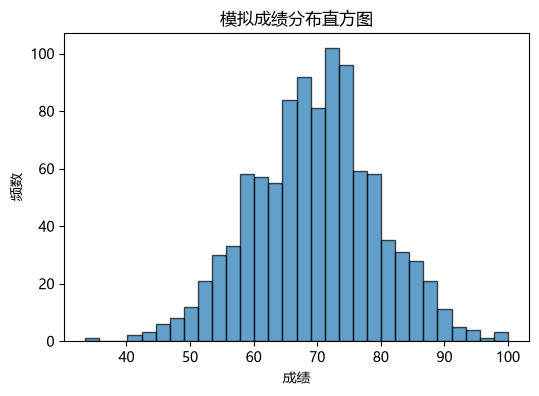

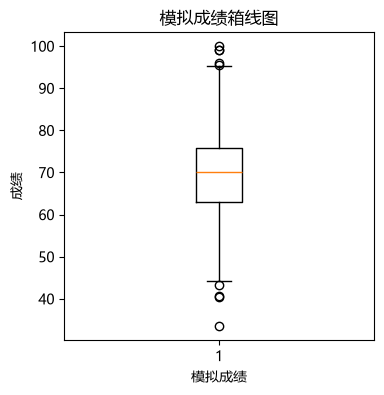

In [16]:
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

valid_scores = scores_nan[~np.isnan(scores_nan)]

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(valid_scores, bins=30, edgecolor="black", alpha=0.7)
ax.set_title("模拟成绩分布直方图")
ax.set_xlabel("成绩")
ax.set_ylabel("频数")
plt.show()

fig, ax = plt.subplots(figsize=(4, 4))
ax.boxplot(valid_scores)
ax.set_title("模拟成绩箱线图")
ax.set_xlabel("模拟成绩")
ax.set_ylabel("成绩")
plt.show()

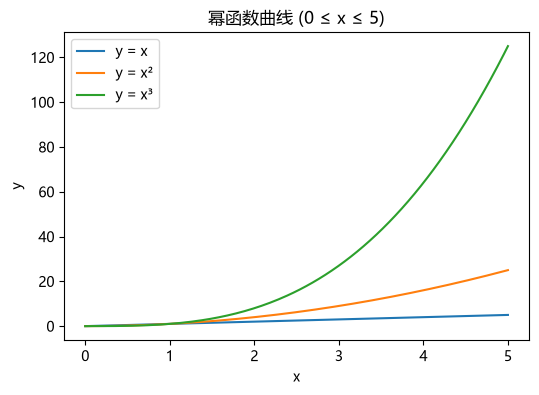

In [17]:
x = np.linspace(0, 5, 200)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(x, x, label="y = x")
ax.plot(x, x**2, label="y = x²")
ax.plot(x, x**3, label="y = x³")
ax.set_title("幂函数曲线 (0 ≤ x ≤ 5)")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
plt.show()

**解释**：直方图用于观察成绩的分布形状；箱线图用于观察中位数、四分位数和离群值。三条幂函数曲线中，$x^3$ 增长最快，$x$ 为直线，$x^2$ 介于两者之间。

---
## 实验4：pandas Series、DataFrame 与内存中的 CSV 读写

### 1. 创建 DataFrame 并计算总分、平均分

In [18]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}

df = pd.DataFrame(records).set_index("Name")
subjects = ["Math", "English", "Python"]

df["Total"] = df[subjects].sum(axis=1)
df["Average"] = df[subjects].mean(axis=1)

print("行索引:", df.index.tolist())
print("列名:", df.columns.tolist())
print("\n前 3 行:")
print(df.head(3))
print("\n基本统计信息:")
print(df.describe())

行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名: ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前 3 行:
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息:
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


**说明**：`set_index("Name")` 把姓名设为行索引；`Total` 和 `Average` 分别按行求和、求平均。

### 2. loc / iloc 与筛选

In [19]:
print("loc['Carol']:")
print(df.loc["Carol"])
print("\niloc[2] (第 3 行，下标从 0 开始):")
print(df.iloc[2])
print("\n平均分不低于 80 的学生:")
print(df[df["Average"] >= 80])

loc['Carol']:
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

iloc[2] (第 3 行，下标从 0 开始):
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

平均分不低于 80 的学生:
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


**解释**：`loc` 按标签（姓名）索引，`iloc` 按整数位置索引；Carol 是第 3 行，所以位置是 2。布尔筛选 `df[df["Average"] >= 80]` 保留满足条件的行。

### 3. mean(axis=0) 与 mean(axis=1)

In [20]:
print("三科列均值 (axis=0):")
print(df[subjects].mean(axis=0))
print("\n每名学生行均值 (axis=1):")
print(df[subjects].mean(axis=1))

三科列均值 (axis=0):
Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

每名学生行均值 (axis=1):
Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


**解释**：`axis=0` 沿着行方向压缩，得到每一列（每科）的均值；`axis=1` 沿着列方向压缩，得到每一行（每名学生）的均值，结果与 `Average` 列相同。

### 4. apply()、agg() 与 rank()

In [21]:
df["最高分"] = df[subjects].apply(max, axis=1)
print("每名学生的三科最高分:")
print(df[["最高分"]])

print("\n每科的最小值、均值、最大值:")
print(df[subjects].agg(["min", "mean", "max"]))

df["总分排名"] = df["Total"].rank(ascending=False, method="min")
print("\n按总分排名:")
print(df[["Total", "总分排名"]])

每名学生的三科最高分:
       最高分
Name      
Alice   95
Bob     80
Carol   91
David   73
Eva     92
Frank   84

每科的最小值、均值、最大值:
           Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

按总分排名:
       Total  总分排名
Name              
Alice    273   1.0
Bob      220   5.0
Carol    265   2.0
David    208   6.0
Eva      257   3.0
Frank    243   4.0


**解释**：`apply(max, axis=1)` 对每一行调用 `max`，得到该行三科的最高分；`agg(["min","mean","max"])` 一次得到每科的三个统计量；`rank(ascending=False)` 按总分从高到低排名，分数越高名次越靠前。

### 5. 分组统计与 transform

In [22]:
print("每组人数:")
print(df.groupby("Group").size())
print("\n每组三科平均分:")
print(df.groupby("Group")[subjects].mean())

df["组内Python均值"] = df.groupby("Group")["Python"].transform("mean")
print("\n为每行增加所在组的 Python 平均分:")
print(df[["Group", "Python", "组内Python均值"]])

每组人数:
Group
A    3
B    3
dtype: int64

每组三科平均分:
            Math    English     Python
Group                                 
A      79.666667  83.333333  87.000000
B      80.000000  78.333333  80.333333

为每行增加所在组的 Python 平均分:
      Group  Python  组内Python均值
Name                           
Alice     A      95   87.000000
Bob       A      80   87.000000
Carol     B      89   80.333333
David     B      70   80.333333
Eva       A      86   87.000000
Frank     B      82   80.333333


**解释**：`groupby("Group")` 按组聚合，`transform("mean")` 把组均值广播回原表的每一行，因此结果的行数与 `df` 相同。

### 6. filter() 保留 Python 平均分不低于 80 的组

In [23]:
kept = df.groupby("Group").filter(lambda g: g["Python"].mean() >= 80)
print("保留的学生:")
print(kept)
print("\n保留的组:", sorted(kept["Group"].unique()))
print("两组 Python 平均分:")
print(df.groupby("Group")["Python"].mean())

保留的学生:
      Group  Math  English  Python  Total    Average  最高分  总分排名  组内Python均值
Name                                                                       
Alice     A    88       90      95    273  91.000000   95   1.0   87.000000
Bob       A    72       68      80    220  73.333333   80   5.0   87.000000
Carol     B    91       85      89    265  88.333333   91   2.0   80.333333
David     B    65       73      70    208  69.333333   73   6.0   80.333333
Eva       A    79       92      86    257  85.666667   92   3.0   87.000000
Frank     B    84       77      82    243  81.000000   84   4.0   80.333333

保留的组: ['A', 'B']
两组 Python 平均分:
Group
A    87.000000
B    80.333333
Name: Python, dtype: float64


**说明**：A 组 Python 平均分为 87.0，B 组为 80.33，均不低于 80，因此两组都保留。若把阈值改为 85，则只会保留 A 组。

### 7. 协方差矩阵与相关系数矩阵

In [24]:
cov_matrix = df[subjects].cov()
corr_matrix = df[subjects].corr()
print("协方差矩阵:")
print(cov_matrix)
print("\n皮尔森相关系数矩阵:")
print(corr_matrix)

print("\nMath 与 Python 的协方差 =", cov_matrix.loc["Math", "Python"])
print("Math 与 Python 的相关系数 =", corr_matrix.loc["Math", "Python"])

协方差矩阵:
              Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667

皮尔森相关系数矩阵:
             Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000

Math 与 Python 的协方差 = 74.93333333333332
Math 与 Python 的相关系数 = 0.8847760993538873


**解释**：Math 与 Python 的协方差为正，说明两科成绩变化方向一致（数学高的学生 Python 也倾向偏高）；相关系数接近 1，说明线性正相关较强。协方差的大小受量纲影响，相关系数则被归一化到 $[-1,1]$，更适合比较不同变量对之间的相关强度。

### 补充：内存中的 CSV 读写（使用实验2.5的成绩表）

In [25]:
import io

buf = io.StringIO()
score_table.to_csv(buf, index=False)
csv_text = buf.getvalue()
print("写入内存的 CSV 前 200 个字符:")
print(csv_text[:200])

buf.seek(0)
score_table_roundtrip = pd.read_csv(buf)
print("\n读回后的形状:", score_table_roundtrip.shape)
print(score_table_roundtrip.head())
print("读回后的缺失值个数:", score_table_roundtrip["成绩"].isna().sum())

写入内存的 CSV 前 200 个字符:
序号,成绩
1,73.04717079754431
2,59.60015893759504
3,77.50451195806457
4,79.40564716391214
5,50.48964811346164
6,56.97820493137682
7,71.27840403167285
8,66.83757407656418
9,69.83198842495712
10,

读回后的形状: (1000, 2)
   序号         成绩
0   1  73.047171
1   2  59.600159
2   3  77.504512
3   4  79.405647
4   5  50.489648
读回后的缺失值个数: 3


**说明**：`io.StringIO` 充当内存中的“文件”，`to_csv` 写入、`read_csv` 读回，全程不落盘。读回后缺失值仍为 NaN，说明 CSV 中的空字段会被 pandas 正确识别为缺失值。